# 07 Causal inference: seeing is not doing

*Teaching material. Not for clinical use.*

At a Role 3 hospital in southern Afghanistan, 896 combat casualties were given at least one unit of red cells, and 293 of them were also given tranexamic acid (E-71). Those given the drug were more severely injured, with a mean injury severity score of 25.2 against 22.5. They still died less often: 17.4% against 23.9%, unadjusted (E-71).

**Before reading on, guess.** Is that proof that tranexamic acid works?

- Yes: the sicker group did better, so the drug must work
- It works, and by at least as much as these figures show
- It works, but by less than these figures show
- These figures alone cannot say how much, or even whether

Write the guess down. It is not marked, and the treatment section below comes back to it.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch

from inference_labs.lenses import causal as c

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID, PALE, GREY = "#7f2704", "#d9d9d9", "#08306b", "#6baed6", "#969696"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", None)

## The idea, before any medicine

Look down a list of house fires. The more fire engines were sent, the more damage was done. Should the fire service send fewer? No: big fires get more engines and do more damage, and the size of the fire drives both. Seeing two things go together, engines and damage, does not say what would happen if one of them were changed. To learn that, the engines would have to be decided by something that has nothing to do with the fire, such as a coin; or everything that decides them would have to be measured, and like compared with like.

Medicine has the same pattern. Models learned that asthma lowers the risk of dying of pneumonia, because asthmatic patients went straight to intensive care (E-60). The care that the asthma brought, not the asthma, did the protecting.

**Plain.** Seeing that two things go together is not the same as knowing what happens if you change one. To learn that, you must intervene, or argue very carefully. Military medicine can rarely toss the coin, so it has to learn where observation goes wrong: who was treated and why, who lived long enough to be treated, and who reached care to be counted.

**Developer.** Draw the graph first: one node for each variable, one arrow for each direct cause. Where every arrow into the treatment comes from recorded variables $X$, fit the chance of treatment $e(X)$ by logistic regression, weight each treated casualty by $1/e(X)$ and each untreated one by $1/(1-e(X))$, and compare the weighted shares who died: they stand in for the two arms of a trial no one ran. The cost is one regression. In the library, `causal.chance_of_treatment` is the constructed allocation used below, and `causal.estimates(seed, n, strength)` returns the naive reading, the two weighted readings and the true value for every delay band.

**Technical.** With potential outcomes $Y(1)$ and $Y(0)$ and treatment $T$, the average effect is $E[Y(1) - Y(0)]$. The naive contrast $E[Y \mid T=1] - E[Y \mid T=0]$ equals it when $T$ is independent of $(Y(1), Y(0))$, which a coin guarantees. Otherwise, if $T$ is independent of $(Y(1), Y(0))$ given $X$ (no unmeasured cause of both) and $0 < e(X) < 1$ (positivity), then $E[Y(t)] = E[\mathbb{1}\{T=t\}\,Y / P(T=t \mid X)]$, estimated here by the weighted mean normalised within each arm. Neither condition can be checked from the data. E-117 puts it in general form: causal questions need knowledge of the causal structure that the data alone do not supply. Survival bias breaks the first condition in its own way: where a treatment can only be received by the living, who is treated depends on how soon each would have died.

### Three tasks

E-117 separates three tasks of data science and gives an example of each from health records. The right-hand column sorts this notebook's anchors into them. The sorting is this notebook's own, not E-117's.

| Task | E-117's example | This notebook's anchors |
|---|---|---|
| Description | How can women with a history of stroke be grouped? | E-81: killed in action before and after the sixty-minute mandate, which its authors say allows only descriptive interpretation. E-71's unadjusted mortality |
| Prediction | What is the probability of a stroke next year? | E-85: when bleeding deaths happen after admission. The scan's accuracy (E-16, a civilian helicopter service; E-14) |
| Counterfactual prediction | Will starting a statin reduce the risk? | E-19 to E-21: CRASH-2, a randomised civilian trial. E-80: the plasma ratio treated as changing over time. E-123: weighting, with rival explanations tested |

E-120's finding, that mortality was lowest where the dose given matched an algorithm's recommendation, is a description put to a counterfactual question; it is taken up in the treatment section.

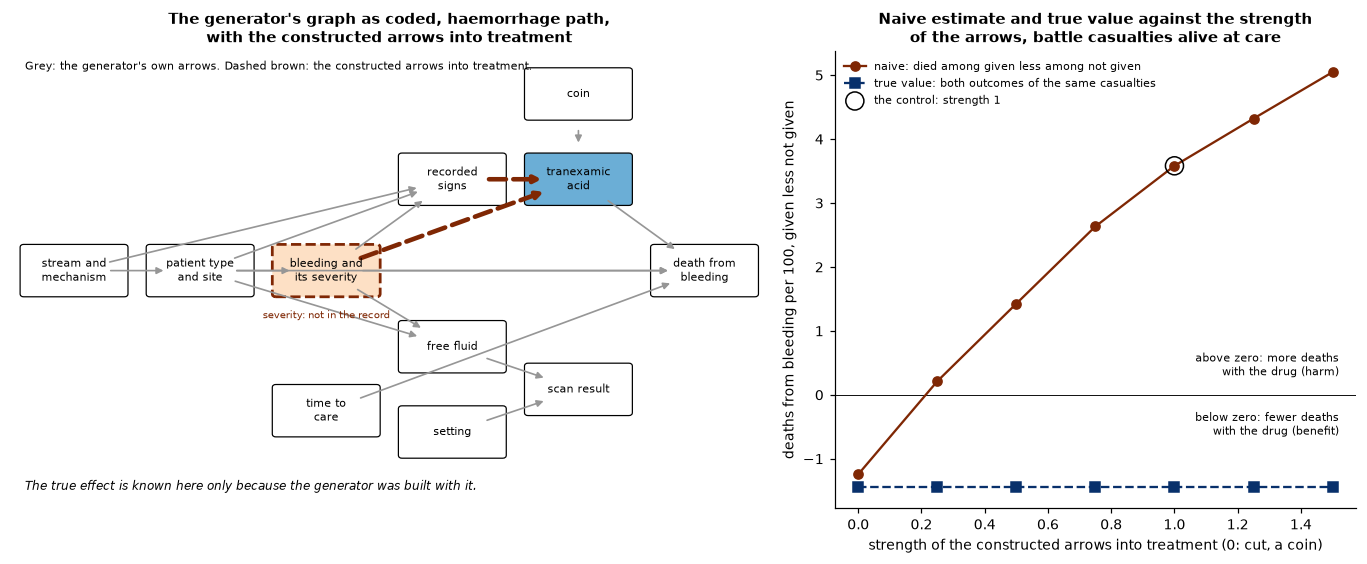

In [2]:
# Central figure: cutting the arrow. The control: change it and run the cell again.
STRENGTH = 1.0     # strength of the constructed arrows into treatment; 0 cuts them, leaving a coin

curve = c.strength_curve()
now = c.estimates(strength=STRENGTH)[c.ALL]
nodes = {"stream and\nmechanism": (0.0, 3.0), "patient type\nand site": (1.8, 3.0),
         "bleeding and\nits severity": (3.6, 3.0), "recorded\nsigns": (5.4, 4.5), "free fluid": (5.4, 1.75),
         "setting": (5.4, 0.35), "scan result": (7.2, 1.05), "time to\ncare": (3.6, 0.7), "coin": (7.2, 5.9),
         "tranexamic\nacid": (7.2, 4.5), "death from\nbleeding": (9.0, 3.0)}
coded = [("stream and\nmechanism", "patient type\nand site"), ("patient type\nand site", "bleeding and\nits severity"),
         ("bleeding and\nits severity", "recorded\nsigns"), ("patient type\nand site", "recorded\nsigns"),
         ("stream and\nmechanism", "recorded\nsigns"), ("bleeding and\nits severity", "free fluid"),
         ("patient type\nand site", "free fluid"), ("free fluid", "scan result"), ("setting", "scan result"),
         ("bleeding and\nits severity", "death from\nbleeding"), ("patient type\nand site", "death from\nbleeding"),
         ("time to\ncare", "death from\nbleeding"), ("tranexamic\nacid", "death from\nbleeding"),
         ("coin", "tranexamic\nacid")]
constructed = [("recorded\nsigns", "tranexamic\nacid"), ("bleeding and\nits severity", "tranexamic\nacid")]

fig, (ax, bx) = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1.45, 1]})


def arrow(a, b, **kw):
    (x0, y0), (x1, y1) = nodes[a], nodes[b]
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", shrinkA=24, shrinkB=24, **kw))


for a, b in coded:
    arrow(a, b, color=GREY, lw=1.1)
for a, b in constructed:
    if STRENGTH > 0:
        arrow(a, b, color=DARK, lw=0.8 + 2.2 * STRENGTH, linestyle="--")
    else:
        (x0, y0), (x1, y1) = nodes[a], nodes[b]
        ax.plot([x0 + 0.35 * (x1 - x0)], [y0 + 0.35 * (y1 - y0)], marker="x", ms=14, mew=3, color=DARK)
for name, (x, y) in nodes.items():
    hidden_node = name == "bleeding and\nits severity"
    ax.add_patch(FancyBboxPatch((x - 0.72, y - 0.38), 1.44, 0.76, boxstyle="round,pad=0.05",
                                facecolor=PALE if name == "tranexamic\nacid" else ("#fde0c5" if hidden_node else "white"),
                                edgecolor=DARK if hidden_node else "black", linestyle="--" if hidden_node else "-",
                                linewidth=1.8 if hidden_node else 0.8, zorder=2))
    ax.text(x, y, name, ha="center", va="center", fontsize=7.5, zorder=3)
ax.text(3.6, 2.35, "severity: not in the record", ha="center", va="top", fontsize=6.5, color=DARK)
ax.text(-0.7, 6.3, "Grey: the generator's own arrows. Dashed brown: the constructed arrows into treatment.",
        fontsize=7)
ax.text(-0.7, -0.6, "The true effect is known here only because the generator was built with it.", fontsize=8,
        style="italic")
ax.set_xlim(-0.9, 9.9)
ax.set_ylim(-0.9, 6.6)
ax.axis("off")
ax.set_title("The generator's graph as coded, haemorrhage path,\nwith the constructed arrows into treatment")

bx.axhline(0, color="black", linewidth=0.6)
bx.plot(curve.index, curve["naive"], "o-", color=DARK, label="naive: died among given less among not given")
bx.plot(curve.index, curve["true value"], "s--", color=MID, label="true value: both outcomes of the same casualties")
bx.scatter([STRENGTH], [now["naive"].difference], s=140, facecolor="none", edgecolor="black", zorder=4,
           label=f"the control: strength {STRENGTH:g}")
bx.text(1.52, 0.25, "above zero: more deaths\nwith the drug (harm)", fontsize=7, ha="right", va="bottom")
bx.text(1.52, -0.25, "below zero: fewer deaths\nwith the drug (benefit)", fontsize=7, ha="right", va="top")
bx.set_xlabel("strength of the constructed arrows into treatment (0: cut, a coin)")
bx.set_ylabel("deaths from bleeding per 100, given less not given")
bx.set_title("Naive estimate and true value against the strength\nof the arrows, battle casualties alive at care")
bx.legend(fontsize=7, loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

The left panel is the generator's graph as its code samples it, drawn for battle casualties, the only ones it gives the drug to, and for the haemorrhage path: chest injury, head injury and sepsis also feed the signs and are not drawn. Among battle casualties the generator gives tranexamic acid by a coin with a chance of one half, and nothing else points into it. Each casualty also carries both outcomes, death from bleeding with the drug and without it, so the true effect is the difference between the two over the same casualties. **The true effect is known here only because the generator was built with it.**

The dashed arrows are constructed, an assumption: a record in which the drug is given more often to casualties with abnormal signs and to those bleeding more heavily, how heavily being something a medic sees at the wound and a record does not hold. Their strength is the control. At the default strength of 1 the naive comparison, the share who died among those given the drug less the share among those not given it, says the drug is followed by more deaths: those given it were bleeding more, and the bleeding, not the drug, killed them. Cut the arrows, so that only the coin decides, and the naive comparison lands on the true value. The casualties, their outcomes and the coin are the same at every strength; only who is given the drug changes.

In [3]:
cut, full = c.estimate_spread(0.0), c.estimate_spread(c.DEFAULT_STRENGTH)
for strength, table in ((0.0, cut), (c.DEFAULT_STRENGTH, full)):
    naive = table[(table["band"] == c.ALL) & (table["estimator"] == "naive")]["less true"]
    print(f"Strength {strength:g}: naive estimate less the true value, deaths from bleeding per 100, "
          f"{c.spread_words(naive, 2, ' per 100')} (mechanism)")
curve.round(2)

Strength 0: naive estimate less the true value, deaths from bleeding per 100, a tie: no detectable difference (the difference runs from -0.40 to +0.45 per 100 across 20 seeds) (mechanism)
Strength 1: naive estimate less the true value, deaths from bleeding per 100, higher: the difference runs from +4.26 to +5.31 per 100 across 20 seeds (mechanism)


,share given,naive,adjusted for every variable the allocation uses,adjusted on the recorded signs alone,true value
strength,,,,,
0.00,0.50,-1.24,-1.33,-1.28,-1.45
0.25,0.47,0.21,-1.31,-0.61,-1.45
0.50,0.44,1.43,-1.51,-0.14,-1.45
0.75,0.41,2.64,-1.59,0.50,-1.45
1.00,0.39,3.58,-1.60,1.12,-1.45
1.25,0.37,4.32,-1.62,1.69,-1.45
1.50,0.35,5.05,-1.02,2.78,-1.45


## By hand: twelve casualties and a coin

Twelve battle casualties bleeding significantly, from the 100,000 synthetic casualties of the military cohort (seed 42), followed from the moment of wounding. They are the first four in the sample whose bleeding death comes within the first hour, the first four whose death comes after it, and the first four who do not die from bleeding. Each one's outcome is read as if untreated, so in this exercise **the drug has no effect on anyone**: whoever is given it dies, or lives, exactly as without it.

A coin is tossed for each. The seed of the coin is one whose tosses fall heads twice and tails twice in each group of four, so the coin alone gives the two sides the same mix. Then the same twelve, with the same coin, are counted a second way: the drug is given at the end of the first hour, so a casualty whom the coin chose but who has died by then is counted as not given.

In [4]:
table = c.hand_twelve()
table

,group,coin,dies from bleeding,hours to death
casualty,,,,
30,dies within the first hour,H,True,0.19
78,dies within the first hour,T,True,0.01
278,dies within the first hour,T,True,0.84
493,dies within the first hour,H,True,0.86
35,dies after the first hour,T,True,1.93
41,dies after the first hour,H,True,4.61
289,dies after the first hour,T,True,3.32
306,dies after the first hour,H,True,1.49
13,does not die from bleeding,H,False,NaN


**Counted on paper.** By the coin: heads fall on casualties 30, 493, 41, 306, 13 and 55. Of these six, four die from bleeding (30, 493, 41 and 306). Tails fall on the other six, of whom four die (78, 278, 35 and 289). Four of six against four of six: no difference, as there should be for a drug with no effect.

Given only if alive at the end of the first hour: casualties 30 and 493 came up heads but die within the hour, at 0.19 and 0.86 hours, so they are not given the drug. The given are 41, 306, 13 and 55: two of the four die. The not given are the six tails and casualties 30 and 493: six of the eight die. Half of the given die against three quarters of the not given. The drug looks protective, and nothing about it changed: two deaths moved from one column to the other because the dead cannot be treated.

In [5]:
# The same counts in plain Python
coins = table["coin"].tolist()
dies = table["dies from bleeding"].tolist()
hours = table["hours to death"].tolist()
by_coin = {"given": 0, "given, died": 0, "not given": 0, "not given, died": 0}
by_hour = dict(by_coin)
for coin, died, h in zip(coins, dies, hours):
    dead_by_hour = died and h <= 1.0
    for counts, given in ((by_coin, coin == "H"), (by_hour, coin == "H" and not dead_by_hour)):
        side = "given" if given else "not given"
        counts[side] += 1
        counts[side + ", died"] += died

# ... and by the library, which must agree
assert by_coin == c.hand_counts(table, "coin")
assert by_hour == c.hand_counts(table, "alive at 1 hour")
pd.DataFrame({"by the coin": by_coin, "by the coin, if alive at 1 hour": by_hour})

,by the coin,"by the coin, if alive at 1 hour"
given,6,4
"given, died",4,2
not given,6,8
"not given, died",4,6


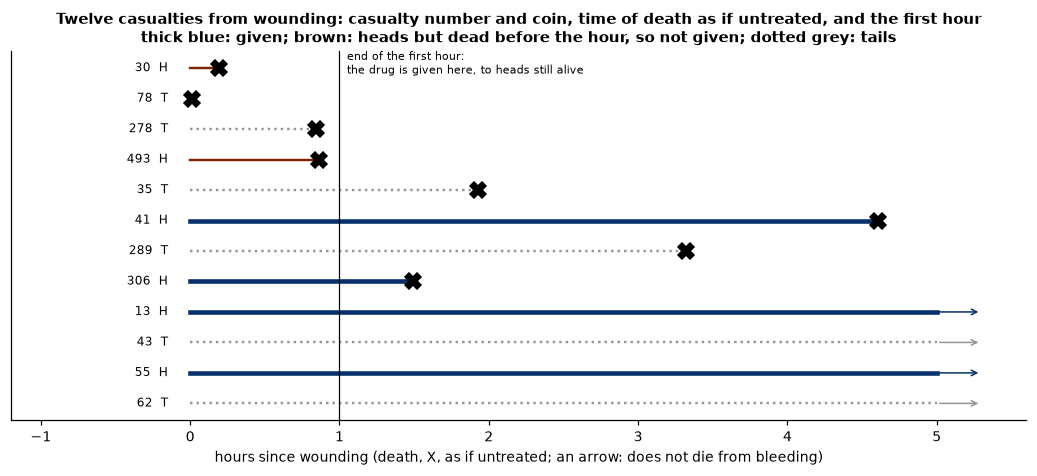

In [6]:
given = c.hand_given(table, "alive at 1 hour")
fig, ax = plt.subplots(figsize=(9.5, 4.4))
for y, (cid, row) in enumerate(table.iloc[::-1].iterrows()):
    g = given[len(table) - 1 - y]
    end = row["hours to death"] if row["dies from bleeding"] else 5.0
    colour = MID if g else (DARK if row["coin"] == "H" else GREY)
    ax.plot([0, end], [y, y], color=colour, linewidth=3 if g else 1.6, linestyle="-" if g else (":" if row["coin"] == "T" else "-"))
    if row["dies from bleeding"]:
        ax.plot(end, y, marker="X", ms=10, color="black")
    else:
        ax.annotate("", (5.3, y), (5.0, y), arrowprops=dict(arrowstyle="->", color=colour))
    ax.text(-0.15, y, f"{cid}  {row['coin']}", ha="right", va="center", fontsize=8)
ax.axvline(1.0, color="black", linewidth=0.8)
ax.text(1.05, 11.6, "end of the first hour:\nthe drug is given here, to heads still alive", fontsize=7, va="top")
ax.set_xlim(-1.2, 5.6)
ax.set_yticks([])
ax.set_xlabel("hours since wounding (death, X, as if untreated; an arrow: does not die from bleeding)")
ax.set_title("Twelve casualties from wounding: casualty number and coin, time of death as if untreated, and the "
             "first hour\nthick blue: given; brown: heads but dead before the hour, so not given; dotted grey: tails")
plt.tight_layout()
plt.show()

### One stratified table

The second count by hand is a table **constructed** for counting, not drawn from the generator. A hundred casualties are given a drug and a hundred are not, in two strata: signs normal and signs abnormal.

In [7]:
display(c.SIMPSON.set_index(["stratum", "drug"]))
shares = c.simpson_shares()
# plain Python: the combined shares from the four cells
given = (1 + 24) / (20 + 80)
not_given = (8 + 8) / (80 + 20)
assert np.isclose(100 * given, shares.loc["combined", "given, %"]) and np.isclose(100 * not_given, shares.loc["combined", "not given, %"])
shares.round(1)

casualties  died
stratum        drug                       
signs normal   given              20     1
               not given          80     8
signs abnormal given              80    24
               not given          20     8

,given: died of,"given, %",not given: died of,"not given, %"
constructed table,,,,
signs normal,1 of 20,5.0,8 of 80,10.0
signs abnormal,24 of 80,30.0,8 of 20,40.0
combined,25 of 100,25.0,16 of 100,16.0


Within each stratum the given die less often: 1 of 20 against 8 of 80 (5% against 10%) when the signs are normal, and 24 of 80 against 8 of 20 (30% against 40%) when they are abnormal. Combined, the given die more often: 25 of 100 against 16 of 100. Both statements are true of the same two hundred people. The combined comparison mixes two strata in different proportions: four in five of the given have abnormal signs, where deaths are common, against one in five of the not given. That is the arrow from signs to treatment in the central figure, at work in four cells.

Which comparison is right depends on the graph, not on the table. Here the signs come before the drug and drive both who is given it and who dies, so the within-stratum comparison is the one that answers "what would the drug do". Had the signs been caused by the drug, splitting by them would have been the error.

## Diagnosis, a weak fit: who gets scanned, and how that biases measured accuracy

Causal inference is mainly a tool for treatment. Its diagnostic use is narrower: a test's accuracy is measured on the patients someone chose to test and whose true state someone chose to confirm, and those choices are causes too. This section is labelled a **weak fit** on the scorecard.

The generator scans every battle casualty for free fluid. Its scan accuracy before hospital is set from E-16, a civilian helicopter service in New South Wales, 98% of whose patients had blunt trauma: sensitivity 25% and specificity 96% for free fluid. In hospital it is set from E-14's pooled figures for free fluid, from 52 studies: 74% and 98%. Both are applied to battle casualties, which is an assumption. In the generator a scan's error depends only on the true state and the setting: a casualty with free fluid is seen to have it with the same chance whatever the signs.

Two selections are constructed, each an assumption:

1. **Scanned only if Priority 1.** Only the casualties whom the MPTT-24, under its figure reading, puts in Priority 1 are scanned.
2. **Confirmed after every positive, one in five negatives.** Everyone is scanned, but the true state is confirmed, by whatever reference a study would use, after every positive scan and after one negative scan in five, chosen by a coin. Accuracy is then counted on the confirmed only.

Each is set beside the same figures measured on every battle casualty against the true state, which only the generator can give. The spread is across 20 further samples of 100,000 (seeds 43 onward).

In [8]:
for setting in c.SETTINGS:
    r = c.scan_accuracy(setting)
    print(f"{c.SETTING_NAMES[setting]}: {r['battle casualties']:,} synthetic battle casualties, "
          f"{r[c.SELECTIONS[0]]['with free fluid']:,} with free fluid; scanned only if Priority 1: "
          f"{r[c.SELECTIONS[1]]['scanned and confirmed']:,}; confirmed: {r[c.SELECTIONS[2]]['scanned and confirmed']:,} "
          f"(mechanism)")
    display(c.scan_table(setting))

scan before hospital: 29,925 synthetic battle casualties, 3,805 with free fluid; scanned only if Priority 1: 13,306; confirmed: 7,595 (mechanism)


,every casualty,scanned only if Priority 1,"confirmed after every positive, one in five negatives","scanned only if Priority 1, less every casualty","confirmed after every positive, one in five negatives, less every casualty"
"scan before hospital, battle casualties",,,,,
"sensitivity, %",25.6,26.1,63.2,a tie: no detectable difference (the difference runs from -0.6 to +1.2 points across 20 seeds),higher: the difference runs from +35.6 to +38.7 points across 20 seeds
"specificity, %",96.1,96.2,83.0,a tie: no detectable difference (the difference runs from -0.2 to +0.2 points across 20 seeds),lower: the difference runs from -13.9 to -12.6 points across 20 seeds
"positive predictive value, %",48.6,57.3,48.6,higher: the difference runs from +6.3 to +9.3 points across 20 seeds,a tie: no detectable difference (the difference runs from +0.0 to +0.0 points across 20 seeds)
"negative predictive value, %",89.9,87.0,89.9,lower: the difference runs from -3.4 to -2.7 points across 20 seeds,a tie: no detectable difference (the difference runs from -0.6 to +0.6 points across 20 seeds)


scan in hospital: 29,925 synthetic battle casualties, 3,805 with free fluid; scanned only if Priority 1: 13,306; confirmed: 8,628 (mechanism)


,every casualty,scanned only if Priority 1,"confirmed after every positive, one in five negatives","scanned only if Priority 1, less every casualty","confirmed after every positive, one in five negatives, less every casualty"
"scan in hospital, battle casualties",,,,,
"sensitivity, %",73.8,74.0,93.3,a tie: no detectable difference (the difference runs from -0.9 to +0.9 points across 20 seeds),higher: the difference runs from +18.2 to +20.8 points across 20 seeds
"specificity, %",98.1,98.1,91.0,a tie: no detectable difference (the difference runs from -0.2 to +0.2 points across 20 seeds),lower: the difference runs from -7.8 to -6.8 points across 20 seeds
"positive predictive value, %",84.7,88.6,84.7,higher: the difference runs from +3.0 to +4.7 points across 20 seeds,a tie: no detectable difference (the difference runs from +0.0 to +0.0 points across 20 seeds)
"negative predictive value, %",96.3,95.1,96.2,lower: the difference runs from -1.6 to -1.1 points across 20 seeds,a tie: no detectable difference (the difference runs from -0.3 to +0.6 points across 20 seeds)


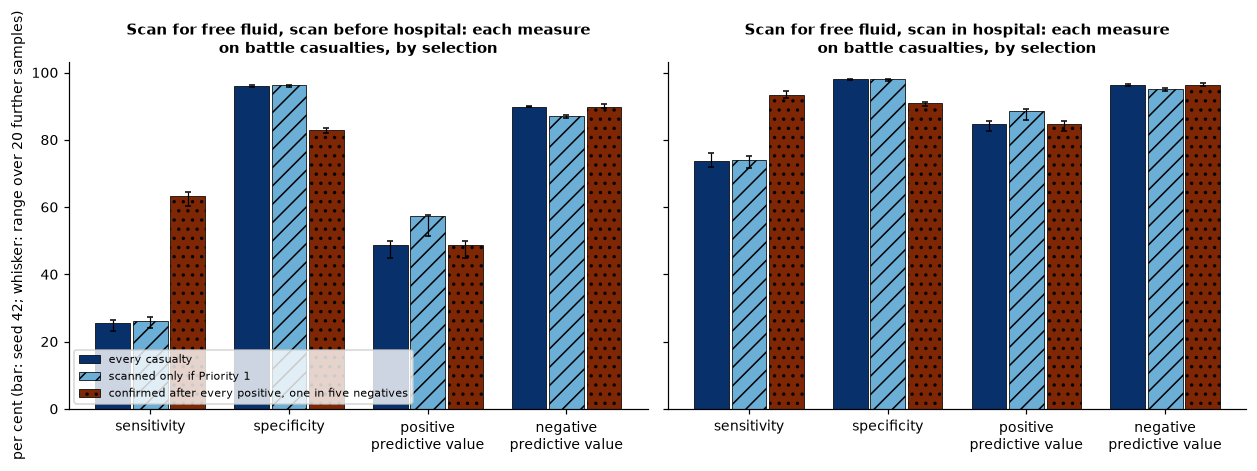

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
x = np.arange(len(c.MEASURES))
styles = ((MID, ""), (PALE, "//"), (DARK, ".."))
for ax, setting in zip(axes, c.SETTINGS):
    r, spread = c.scan_accuracy(setting), c.scan_spread(setting)
    for k, (sel, (colour, hatch)) in enumerate(zip(c.SELECTIONS, styles)):
        values = np.array([100 * r[sel][m] for m in c.MEASURES])
        lo = np.array([100 * spread[f"{sel}: {m}"].min() for m in c.MEASURES])
        hi = np.array([100 * spread[f"{sel}: {m}"].max() for m in c.MEASURES])
        ax.bar(x + (k - 1) * 0.27, values, 0.25, color=colour, hatch=hatch, edgecolor="black", linewidth=0.5,
               label=sel)
        ax.errorbar(x + (k - 1) * 0.27, (lo + hi) / 2, yerr=(hi - lo) / 2, fmt="none", color="black", capsize=2,
                    linewidth=0.8)
    ax.set_xticks(x, ["sensitivity", "specificity", "positive\npredictive value", "negative\npredictive value"])
    ax.set_title(f"Scan for free fluid, {c.SETTING_NAMES[setting]}: each measure\non battle casualties, by selection")
axes[0].set_ylabel("per cent (bar: seed 42; whisker: range over 20 further samples)")
axes[0].legend(fontsize=7, loc="lower left", frameon=True)
plt.tight_layout()
plt.show()

The two selections fail in different places.

**Scanned only if Priority 1.** Sensitivity and specificity are a tie with every casualty in both settings, across the 20 samples, because a scan's error in the generator does not depend on the signs and steps that chose who was scanned. What moves is what a result means: free fluid is commoner among the Priority 1 casualties, so the positive predictive value rises (before hospital from 48.6% to 57.3% in the main sample) and the negative predictive value falls, on every sample. A predictive value carries the population it was measured in.

**Confirmed after every positive, one in five negatives.** Before hospital, the measured sensitivity rises from 25.6% to 63.2% and the specificity falls from 96.1% to 83.0%, on every sample. Every true positive is counted and four in five false negatives are lost from the count, so the scan appears to miss far less than it does; four in five true negatives are lost too, so the false positives loom larger. The positive predictive value does not move, by construction, because every positive is confirmed.

On every casualty, the generator's accuracy is what it was set to be from E-16, a civilian service, and from E-14. The lesson is not about those studies but about the question any accuracy figure invites: who was tested, and whose true state was confirmed?

## Treatment: the effect of tranexamic acid, three ways

This section is about a treatment, and its results are kept apart from the diagnosis results above.

### A trial and an observational study

CRASH-2 randomised 20,211 patients within 8 hours of injury, in 274 hospitals in 40 countries, to tranexamic acid or placebo (E-19). It is a civilian trial. Death due to bleeding was 489 of the 10,060 analysed with tranexamic acid (4.9%) against 574 of the 10,067 with placebo (5.7%), relative risk 0.85 (0.76 to 0.96) (E-19, E-21).

MATTERs, the hook's study, is observational: 896 combat casualties given at least one unit of red cells at a Role 3 hospital in southern Afghanistan, 293 of them given tranexamic acid. Unadjusted mortality was 17.4% against 23.9% (P=.03), the treated more severely injured (mean injury severity score 25.2 against 22.5); among the massively transfused it was 14.4% against 28.1% (E-71).

In [10]:
w, wo = c.CRASH2["bleeding_deaths"]
nw, nwo = c.CRASH2["analysed"]
print(f"CRASH-2, a civilian trial (E-19, E-21): death due to bleeding {w / nw:.2%} against {wo / nwo:.2%}; "
      f"relative risk from the counts {(w / nw) / (wo / nwo):.3f}, reported as {c.CRASH2['rr'][0]:.2f}; "
      f"{100 * (wo / nwo - w / nw):.2f} fewer deaths due to bleeding per 100 with the drug")
a, b = c.E71["mortality"]
ma, mb = c.E71["massive"]
print(f"MATTERs, observational (E-71): mortality {a}% against {b}%, a ratio of {a / b:.2f} and {b - a:.1f} fewer "
      f"deaths per 100 with the drug; massively transfused {ma}% against {mb}%, a ratio of {ma / mb:.2f} and "
      f"{mb - ma:.1f} fewer per 100")

CRASH-2, a civilian trial (E-19, E-21): death due to bleeding 4.86% against 5.70%; relative risk from the counts 0.853, reported as 0.85; 0.84 fewer deaths due to bleeding per 100 with the drug
MATTERs, observational (E-71): mortality 17.4% against 23.9%, a ratio of 0.73 and 6.5 fewer deaths per 100 with the drug; massively transfused 14.4% against 28.1%, a ratio of 0.51 and 13.7 fewer per 100


Both report fewer deaths with the drug; the observational ratios are much further from one. **The answer to the hook** is the last option: an unrandomised comparison can sit far from the truth, in either direction, as the generator shows below, and these figures alone do not show how far, or which way, MATTERs sits. The two studies are not reconciled here, because from these sources they cannot be. What E-71 records is unadjusted mortality among 896 combat casualties given red cells at one hospital, with the treated more severely injured; mortality among the massively transfused; and an odds ratio for survival. What E-19 and E-21 record is death due to bleeding among 20,211 civilian patients randomised within 8 hours of injury. The two differ in population, in design and in the outcome counted, and nothing in the three rows says how the 293 came to be given the drug or when. With only that, the gap between them cannot be divided into a part due to who was treated, a part due to who was studied and a part due to what was counted. Nothing here says MATTERs is wrong. What the generator can show is how far an observational comparison can sit from the truth, and in which direction, when the arrows into treatment are known.

### On the generator, with the arrows known

The casualties are the battle casualties among the 100,000 synthetic casualties of the military cohort (seed 42) who are alive at pre-hospital care, judged by the generator's outcome without tranexamic acid: 29,443 of them. The constructed allocation, an assumption, gives each a chance of the drug from the table below. Each casualty's outcome is then read from the generator's two outcomes: death from bleeding with the drug if given it, without if not.

In [11]:
print("Constructed allocation (an assumption): log odds of being given the drug = strength x (sum of the terms below)")
display(pd.Series(c.ALLOCATION, name="term").to_frame())
print(f"Strength {c.DEFAULT_STRENGTH:g}. The variable '{c.HIDDEN}' is the generator's severity centile for a casualty "
      f"bleeding significantly, and zero for one who is not; a record would not hold it.")
c.balance().round(3)

Constructed allocation (an assumption): log odds of being given the drug = strength x (sum of the terms below)


,term
intercept,-1.5
heart rate 100 or more,1.0
systolic pressure 90 or less,1.0
below alert,1.0
catastrophic haemorrhage,1.0
"how heavily bleeding, as seen at the wound",2.0


Strength 1. The variable 'how heavily bleeding, as seen at the wound' is the generator's severity centile for a casualty bleeding significantly, and zero for one who is not; a record would not hold it.


,given the drug,not given
heart rate 100 or more,0.609,0.328
systolic pressure 90 or less,0.154,0.018
below alert,0.191,0.090
catastrophic haemorrhage,0.065,0.014
"how heavily bleeding, as seen at the wound",0.309,0.089
bleeding significantly,0.529,0.238


The drug goes to those who look worse: those given it are more than twice as likely to be bleeding significantly. Three readings of the record are compared with the truth:

- **Naive**: the share who died among those given the drug, less the share among those not given it.
- **Adjusted for every variable the allocation uses**: inverse probability weighting, the chance of treatment fitted by logistic regression on the four signs and on how heavily the casualty is bleeding.
- **True value**: both outcomes of the same casualties, which only the generator holds.

Each is computed for every delay and for each band of time from injury to pre-hospital care, when the drug is given, in E-22's bands from CRASH-2, a civilian trial. Each is set against the true value across 20 further samples of 100,000.

In [12]:
for band in (c.ALL,) + c.BANDS:
    r = c.estimates()[band]
    print(f"{band}: {r['casualties']:,} casualties, {r['given']:,} given the drug, {r['deaths']:,} die from bleeding "
          f"(mechanism)")
    display(c.estimate_table(band))

every delay: 29,443 casualties, 11,513 given the drug, 1,227 die from bleeding (mechanism)


,"with the drug, per 100","without, per 100","difference, per 100",relative risk,"less the true value, across 20 further samples"
"every delay (29,443 casualties)",,,,,
naive,6.35,2.77,3.58,2.30,higher: the difference runs from +4.26 to +5.31 per 100 across 20 seeds
adjusted for every variable the allocation uses,3.67,5.28,-1.60,0.70,a tie: no detectable difference (the difference runs from -0.67 to +0.67 per 100 across 20 seeds)
adjusted on the recorded signs alone,4.99,3.87,1.12,1.29,higher: the difference runs from +2.39 to +3.31 per 100 across 20 seeds
true value,3.71,5.15,-1.45,0.72,the reference


up to 1 hour: 16,445 casualties, 6,414 given the drug, 726 die from bleeding (mechanism)


,"with the drug, per 100","without, per 100","difference, per 100",relative risk,"less the true value, across 20 further samples"
"up to 1 hour (16,445 casualties)",,,,,
naive,6.64,2.99,3.65,2.22,higher: the difference runs from +4.27 to +5.60 per 100 across 20 seeds
adjusted for every variable the allocation uses,3.81,5.59,-1.78,0.68,a tie: no detectable difference (the difference runs from -0.93 to +0.92 per 100 across 20 seeds)
adjusted on the recorded signs alone,5.20,4.17,1.03,1.25,higher: the difference runs from +2.23 to +3.78 per 100 across 20 seeds
true value,3.85,5.67,-1.82,0.68,the reference


1 to 3 hours: 12,701 casualties, 4,982 given the drug, 493 die from bleeding (mechanism)


,"with the drug, per 100","without, per 100","difference, per 100",relative risk,"less the true value, across 20 further samples"
"1 to 3 hours (12,701 casualties)",,,,,
naive,6.02,2.50,3.52,2.41,higher: the difference runs from +4.10 to +5.47 per 100 across 20 seeds
adjusted for every variable the allocation uses,3.53,4.88,-1.35,0.72,a tie: no detectable difference (the difference runs from -0.84 to +1.09 per 100 across 20 seeds)
adjusted on the recorded signs alone,4.75,3.46,1.29,1.37,higher: the difference runs from +1.83 to +3.64 per 100 across 20 seeds
true value,3.52,4.56,-1.04,0.77,the reference


over 3 hours: 297 casualties, 117 given the drug, 8 die from bleeding (mechanism)


,"with the drug, per 100","without, per 100","difference, per 100",relative risk,"less the true value, across 20 further samples"
over 3 hours (297 casualties),,,,,
naive,4.27,1.67,2.61,2.56,higher: the difference runs from +0.20 to +8.63 per 100 across 20 seeds
adjusted for every variable the allocation uses,2.33,5.02,-2.69,0.46,a tie: no detectable difference (the difference runs from -4.40 to +4.71 per 100 across 20 seeds)
adjusted on the recorded signs alone,3.49,4.55,-1.06,0.77,a tie: no detectable difference (the difference runs from -1.07 to +7.63 per 100 across 20 seeds)
true value,3.70,2.02,1.68,1.83,the reference


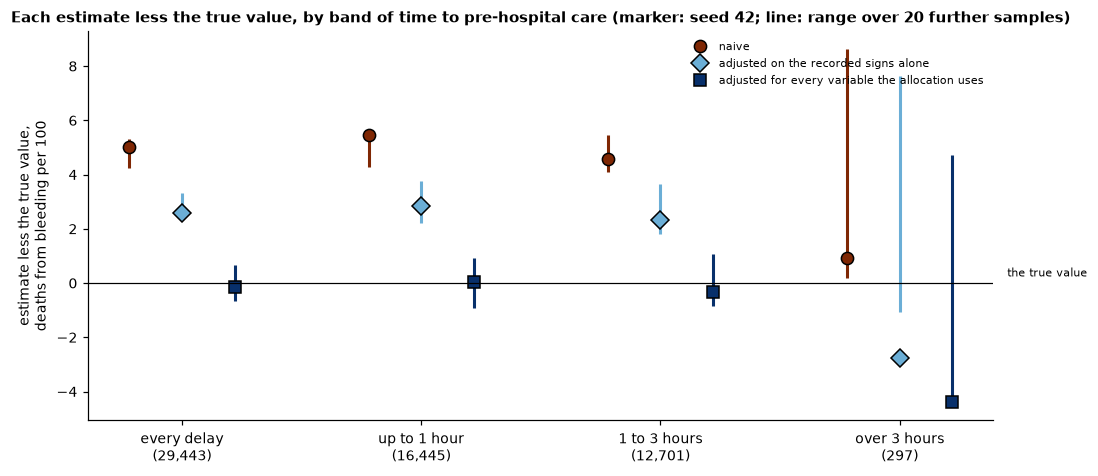

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.4))
bands = (c.ALL,) + c.BANDS
shown = (("naive", DARK, "o"), ("adjusted on the recorded signs alone", PALE, "D"),
         ("adjusted for every variable the allocation uses", MID, "s"))
for k, (name, colour, marker) in enumerate(shown):
    for j, band in enumerate(bands):
        r = c.estimates()[band]
        point = r[name].difference - r["true value"].difference
        s = c.spread_of(band, name)
        ax.vlines(j + (k - 1) * 0.22, s.min(), s.max(), color=colour, linewidth=2)
        ax.plot(j + (k - 1) * 0.22, point, marker=marker, color=colour, markeredgecolor="black", ms=8,
                linestyle="none", label=name if j == 0 else None)
ax.axhline(0, color="black", linewidth=0.8)
ax.text(len(bands) - 0.55, 0.15, "the true value", fontsize=7, va="bottom")
ax.set_xticks(range(len(bands)), [f"{b}\n({c.estimates()[b]['casualties']:,})" for b in bands])
ax.set_ylabel("estimate less the true value,\ndeaths from bleeding per 100")
ax.set_title("Each estimate less the true value, by band of time to pre-hospital care (marker: seed 42; line: range "
             "over 20 further samples)")
ax.legend(fontsize=7, frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

For every delay, the true effect is 1.45 fewer deaths from bleeding per 100 with the drug, a relative risk of 0.72 (mechanism). The naive reading of the record shows 3.58 **more** deaths per 100 among those given the drug, which reads as harm: it is above the true value on every one of the 20 samples. Adjusted for every variable the allocation uses, the reading is 1.60 fewer per 100, a tie with the true value across the samples. The bands up to 1 hour and from 1 to 3 hours behave the same way. The band over 3 hours holds 297 casualties and 8 deaths. There the naive reading is still above the true value on every sample, but the two adjusted readings cannot be told from it: their spread across samples covers several deaths per 100 on either side.

The direction of the naive error comes from the constructed arrows: the drug goes to those bleeding more, who die more. In MATTERs the treated were more severely injured and still died less often (E-71). On the generator, giving the drug to the worse-injured pushes the naive comparison towards harm, and the failure below shows survival bias pushing it towards benefit. Which of these, if either, acted in MATTERs, and how strongly, its row does not record. That reading is this notebook's own.

### An unmeasured cause

Now suppose the record holds the signs but not how heavily the casualty is bleeding, which is the usual case. The adjustment is repeated on the four recorded signs alone.

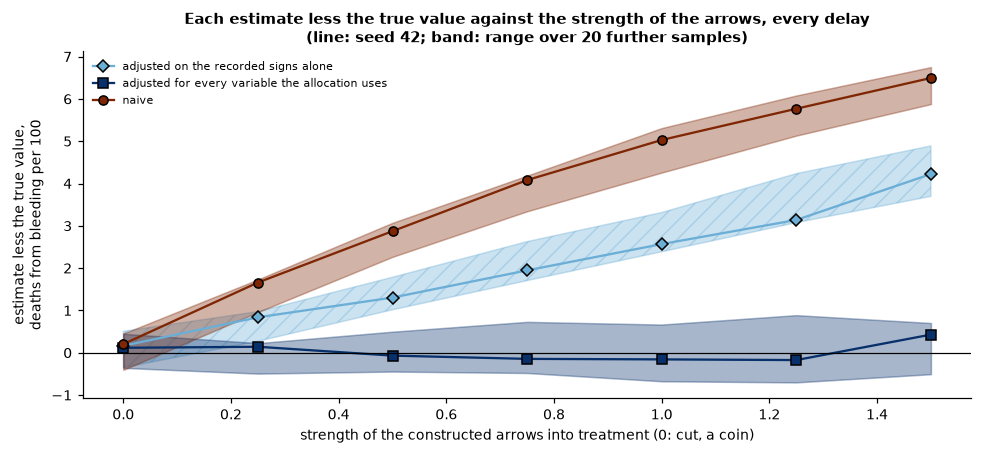

At strength 1, adjusted on the recorded signs alone, less the true value: higher: the difference runs from +2.39 to +3.31 per 100 across 20 seeds (mechanism)


In [14]:
spreads = {s: c.estimate_spread(float(s)) for s in c.STRENGTHS}
fig, ax = plt.subplots(figsize=(9, 4.2))
for name, colour, marker in (("adjusted on the recorded signs alone", PALE, "D"),
                             ("adjusted for every variable the allocation uses", MID, "s"),
                             ("naive", DARK, "o")):
    lo = [spreads[s][(spreads[s]["band"] == c.ALL) & (spreads[s]["estimator"] == name)]["less true"].min() for s in c.STRENGTHS]
    hi = [spreads[s][(spreads[s]["band"] == c.ALL) & (spreads[s]["estimator"] == name)]["less true"].max() for s in c.STRENGTHS]
    ax.fill_between(c.STRENGTHS, lo, hi, color=colour, alpha=0.35, hatch="//" if marker == "D" else None)
    ax.plot(c.STRENGTHS, c.strength_curve()[name] - c.strength_curve()["true value"], marker=marker, color=colour,
            markeredgecolor="black", label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("strength of the constructed arrows into treatment (0: cut, a coin)")
ax.set_ylabel("estimate less the true value,\ndeaths from bleeding per 100")
ax.set_title("Each estimate less the true value against the strength of the arrows, every delay\n(line: seed 42; "
             "band: range over 20 further samples)")
ax.legend(fontsize=7, frameon=False, loc="upper left")
plt.tight_layout()
plt.show()
signs_only = c.spread_of(c.ALL, "adjusted on the recorded signs alone")
print(f"At strength {c.DEFAULT_STRENGTH:g}, adjusted on the recorded signs alone, less the true value: "
      f"{c.spread_words(signs_only, 2, ' per 100')} (mechanism)")

Weighting on the signs alone removes part of the naive error: the reading falls from 3.58 more deaths per 100 to 1.12 more. It is still wrong, and on the wrong side: above the true value on every one of the 20 samples, by between 2.39 and 3.31 deaths per 100. The signs carry some of how heavily a casualty is bleeding, since the generator draws heart rate and systolic pressure from it, but not all of it. The part they miss still drives both who is given the drug and who dies. With the arrows cut, every reading is a tie with the truth across the 20 samples; the stronger the arrows, the further the signs-alone reading strays, while the reading adjusted for every variable the allocation uses stays a tie at every strength drawn.

**What weighting can and cannot remove.** E-123 re-analysed the golden hour data, 4,542 US casualties in Afghanistan from 2001 to 2014, with inverse probability weighting for selection, and then tested five rival explanations. It found no gradual time trend (adjusted odds ratio 0.99, 0.94 to 1.03). For military injury severity scores of 25 or more, the odds of being killed in action were 0.17 (0.06 to 0.51) with prehospital transfusion when needed and 0.61 (0.51 to 0.74) with transport within one hour; a simulation with transport times unchanged gave 135 more killed in action (105 to 164), against the 359 lives saved estimated in the first paper (E-81). Beside E-123's transfusion result sits E-81's own contrast among the critically injured: 6.8% (40 of 589) of those who received a blood transfusion were killed in action against 51.0% (249 of 488) of those who did not, with the authors listing survival bias in the transfusion analysis among their limitations (E-81).

This notebook's reading, not E-123's: weighting on recorded variables balances those variables between the groups compared, as the generator shows when every arrow into treatment is recorded. It cannot balance a cause the records do not hold, as the signs-alone reading shows. Whether such a cause remains in E-123's data, these figures cannot say.

### An association to question

E-120, the original sepsis reinforcement learning study, trained a policy on 17,083 admissions from one hospital's database and tested it on 79,073 from 128 hospitals. It reports that mortality was lowest where the dose given matched the policy's recommendation, and its authors state that the policy needs prospective evaluation (E-120). That is an association, and it is offered here as one to question. This notebook's reading, not the paper's: patients whose care departs from the usual may differ in ways the records do not hold, so the association may be confounded, as the hidden variable confounds the signs-alone reading above.

## The failure: survival bias producing a benefit from a drug with none

Back on the generator, take its battle casualties bleeding significantly, followed from the moment of wounding: 10,834 of them in the main sample. Read each one's outcome as if untreated, so **the drug has no effect on anyone**. The generator's own coin says who is meant to get the drug, at their time to pre-hospital care; it is given only to those still alive then, and a casualty meant to get it who dies first is counted as not given. The generator's death times run from injury on a hazard fitted to E-85's hourly rates, which were measured from hospital admission: an assumption.

Two comparisons of the same casualties:

- **Naive**: those given the drug against everyone else.
- **Aligned at a common start**: each casualty enters at the moment the drug would be given, if alive then; those given it are compared with those not meant to get it, both counted from that moment.

The spread is across 20 further samples of 100,000 (seeds 43 onward).

In [15]:
sb = c.survival_bias()
spread_s = c.survival_spread()
print(f"{sb['casualties']:,} battle casualties bleeding significantly; {sb['meant']:,} meant to get the drug, of whom "
      f"{sb['meant, died first']:,} die before it can be given; {sb['given']:,} given it (mechanism)")
print(f"Naive: {sb['naive'].words()}")
print(f"Aligned at a common start ({sb['aligned casualties']:,} alive when the drug would be given): {sb['aligned'].words()}")
print(f"Across {len(spread_s)} further samples: naive relative risk from {spread_s['naive relative risk'].min():.2f} to "
      f"{spread_s['naive relative risk'].max():.2f}; aligned difference, "
      f"{c.spread_words(spread_s['aligned difference'], 2, ' per 100')}")

10,834 battle casualties bleeding significantly; 5,421 meant to get the drug, of whom 241 die before it can be given; 5,180 given it (mechanism)
Naive: 14.71 per 100 with the drug against 21.88 without: 7.17 fewer deaths per 100 with the drug (relative risk 0.67)
Aligned at a common start (10,352 alive when the drug would be given): 14.71 per 100 with the drug against 14.60 without: 0.11 more deaths per 100 with the drug (relative risk 1.01)
Across 20 further samples: naive relative risk from 0.63 to 0.71; aligned difference, a tie: no detectable difference (the difference runs from -1.25 to +1.52 per 100 across 20 seeds)


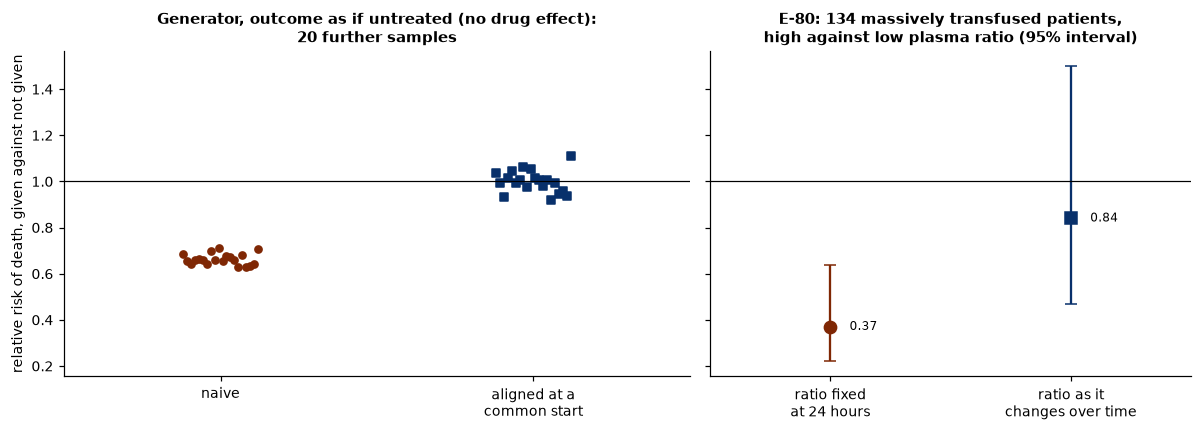

In [16]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]}, sharey=True)
jitter = np.linspace(-0.12, 0.12, len(spread_s))
ax.scatter(0 + jitter, spread_s["naive relative risk"], color=DARK, marker="o", s=22, label="naive")
ax.scatter(1 + jitter, spread_s["aligned relative risk"], color=MID, marker="s", s=22, label="aligned at a common start")
ax.axhline(1, color="black", linewidth=0.8)
ax.set_xticks([0, 1], ["naive", "aligned at a\ncommon start"])
ax.set_xlim(-0.5, 1.5)
ax.set_ylabel("relative risk of death, given against not given")
ax.set_title("Generator, outcome as if untreated (no drug effect):\n20 further samples")
for k, (name, (rr, lo, hi), colour, marker) in enumerate((
        ("ratio fixed\nat 24 hours", c.E80["fixed"], DARK, "o"),
        ("ratio as it\nchanges over time", c.E80["changing"], MID, "s"))):
    bx.errorbar(k, rr, yerr=[[rr - lo], [hi - rr]], fmt=marker, color=colour, capsize=4, ms=8)
    bx.text(k + 0.08, rr, f"{rr:.2f}", va="center", fontsize=8)
bx.axhline(1, color="black", linewidth=0.8)
bx.set_xticks([0, 1], ["ratio fixed\nat 24 hours", "ratio as it\nchanges over time"])
bx.set_xlim(-0.5, 1.5)
bx.set_title(f"E-80: {c.E80['patients']} massively transfused patients,\nhigh against low plasma ratio (95% interval)")
plt.tight_layout()
plt.show()

The naive comparison finds about a third fewer deaths among those given the drug, a relative risk between 0.63 and 0.71 on the 20 samples, for a drug that does nothing. The 241 casualties the coin chose who died before they could be given it are counted among the not given, and the not given also hold every early death among those the coin did not choose. Aligned at a common start, so that each casualty is counted only from the moment the drug would have been given and only if alive then, the difference is a tie across the 20 samples.

E-80 shows the same move in real data. Among 134 massively transfused patients, a high plasma ratio fixed at 24 hours had a relative risk of death of 0.37 (0.22 to 0.64); with the ratio treated as changing over time, it was 0.84 (0.47 to 1.50). 54% of the deaths came in the first 6 hours, when the ratio was still low (E-80). E-81's transfusion contrast, 6.8% killed in action among the critically injured who received a blood transfusion against 51.0% among those who did not, is flagged by its own authors for survival bias (E-81).

The same mechanism reaches inside a randomised trial. In CRASH-2, a civilian trial, blood products were given to 50.4% with tranexamic acid against 51.3% with placebo, relative risk 0.98 (0.96 to 1.01), and the authors note that patients who survive because of treatment have more opportunity to be transfused (E-20). Randomisation protects the comparison it was set up for, not every outcome counted among those who lived to receive it.

### Selection on reaching care

Killed in action and died of wounds divide the dead by whether they reached care alive: to be killed in action is to die before reaching a facility. Among 21,089 US casualties in Afghanistan from 2001 to 2014, killed in action was 16.0% (386 of 2,411) before the 2009 sixty-minute evacuation mandate and 9.9% (964 of 9,755) after it; died of wounds was 4.1% before and 4.3% after (P=.71). Only 37.3% of casualties had matched flight and facility data (E-81). The authors list historical controls, post hoc analysis of non-randomised data, survival bias in the transfusion analysis and several factors changing at once, so that only descriptive interpretation was viable (E-81). **The fall in killed in action is not attributed to the mandate here.**

The structure is the one above: a death counted after reaching care needs a casualty who reached care alive. On the generator, take the battle casualties bleeding significantly, each outcome read as if untreated, and halve every time from injury to Role 2, which is constructed. In the generator reaching Role 2 saves no one, so the same casualties die at the same times whatever the clock of evacuation; only which side of arrival each death falls on changes.

as drawn: 1,999 of 10,834 die from bleeding; 896 before reaching Role 2 (8.3 per 100); 1,103 of the 9,938 who reach it alive die after (11.1 per 100 reaching it) (mechanism)
times to Role 2 halved: 1,999 of 10,834 die from bleeding; 462 before reaching Role 2 (4.3 per 100); 1,537 of the 10,372 who reach it alive die after (14.8 per 100 reaching it) (mechanism)
Across 20 further samples, halved less as drawn: before Role 2, lower: the difference runs from -4.4 to -3.6 per 100 across 20 seeds; after reaching it, higher: the difference runs from +3.3 to +4.0 per 100 reaching it across 20 seeds; deaths from bleeding the same on every sample: True


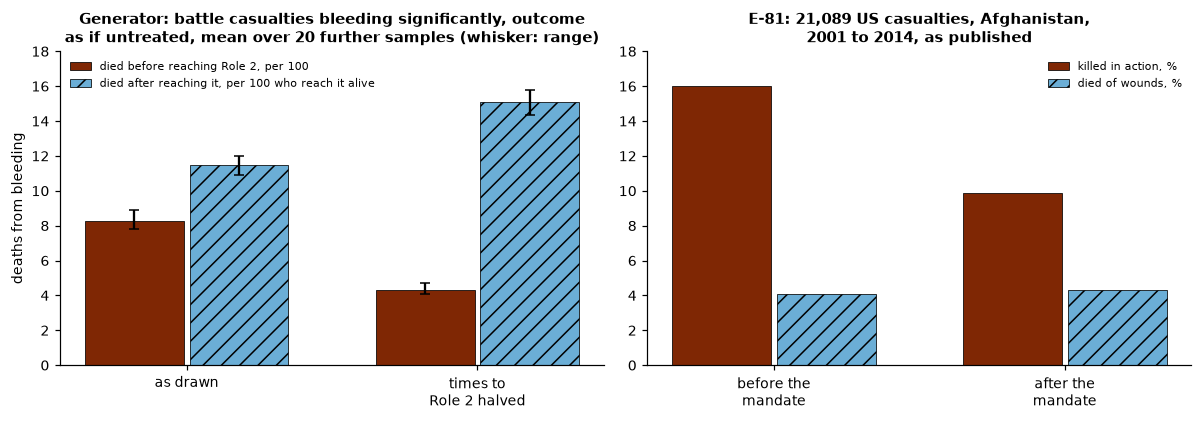

In [17]:
as_drawn, faster = c.reaching_care(), c.reaching_care(factor=c.FASTER)
spread_r = c.reaching_spread()
for name, r in (("as drawn", as_drawn), ("times to Role 2 halved", faster)):
    print(f"{name}: {r['died']:,} of {r['casualties']:,} die from bleeding; {r['before Role 2']:,} before reaching "
          f"Role 2 ({r['before, per 100']:.1f} per 100); {r['died after reaching']:,} of the {r['reached alive']:,} who "
          f"reach it alive die after ({r['after, per 100 reaching']:.1f} per 100 reaching it) (mechanism)")
print(f"Across {len(spread_r)} further samples, halved less as drawn: before Role 2, "
      f"{c.spread_words(spread_r['before, faster'] - spread_r['before, as drawn'], 1, ' per 100')}; after reaching it, "
      f"{c.spread_words(spread_r['after, faster'] - spread_r['after, as drawn'], 1, ' per 100 reaching it')}; "
      f"deaths from bleeding the same on every sample: {bool((spread_r['died, as drawn'] == spread_r['died, faster']).all())}")

fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 3.9))
labels = ["as drawn", "times to\nRole 2 halved"]
for k, key in enumerate(("as drawn", "faster")):
    before, after = spread_r[f"before, {key}"], spread_r[f"after, {key}"]
    for j, (s, colour, hatch) in enumerate(((before, DARK, ""), (after, PALE, "//"))):
        x = k + (j - 0.5) * 0.36
        ax.bar(x, s.mean(), 0.34, color=colour, hatch=hatch, edgecolor="black", linewidth=0.5,
               label=(["died before reaching Role 2, per 100", "died after reaching it, per 100 who reach it alive"][j]
                      if k == 0 else None))
        ax.errorbar(x, (s.min() + s.max()) / 2, yerr=(s.max() - s.min()) / 2, color="black", capsize=3, fmt="none")
ax.set_xticks([0, 1], labels)
ax.set_ylabel("deaths from bleeding")
ax.set_title("Generator: battle casualties bleeding significantly, outcome\nas if untreated, mean over 20 further samples (whisker: range)")
ax.set_ylim(0, 18)
ax.legend(fontsize=7, frameon=False, loc="upper left")
before_m, after_m = c.E81["kia_before"][2], c.E81["kia_after"][2]
for k, (kia, dow) in enumerate(((before_m, c.E81["dow"][0]), (after_m, c.E81["dow"][1]))):
    bx.bar(k - 0.18, kia, 0.34, color=DARK, edgecolor="black", linewidth=0.5, label="killed in action, %" if k == 0 else None)
    bx.bar(k + 0.18, dow, 0.34, color=PALE, hatch="//", edgecolor="black", linewidth=0.5,
           label="died of wounds, %" if k == 0 else None)
bx.set_xticks([0, 1], ["before the\nmandate", "after the\nmandate"])
bx.set_title("E-81: 21,089 US casualties, Afghanistan,\n2001 to 2014, as published")
bx.set_ylim(0, 18)
bx.legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.show()

On the generator, halving the times to Role 2 roughly halves the deaths before arrival and raises the share who die after arriving, on every sample, while the number who die from bleeding is the same. Nothing about care changed; more of the dying reached Role 2 before they died. A rate of death among those who reach care alive is conditioned on reaching it, so it moves with how many of the dying get there, as well as with the care they receive. So E-81's two rates are read together here, not apart: the figures on the generator show the structure, not what happened in Afghanistan.

## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed on the generator and carry the **mechanism** label; axes 3, 4 and 5 are stated; axis 7 is net benefit at a threshold of 0.10 for every lens (D-26).

The diagnosis column is the scan for free fluid on the battle casualties among the 100,000 synthetic casualties (seed 42), measured against the true state of every casualty and under the two constructed selections. Fit is **weak**: the lens asks how a measured accuracy is biased, not who has free fluid. The baseline columns are the MPTT-24's Priority 1 against free fluid, which the rule was not written for, under the figure reading as published and the text reading as validated (D-24); D-23's statement goes with the rule's accuracy on the generator. The treatment column is the effect of tranexamic acid on death from bleeding among the battle casualties alive at pre-hospital care, under the constructed allocation, read three ways beside its true value. Fit is **native**. The rule states no effect of a treatment, so the baseline of each treatment row is empty (NaN).

In [18]:
c.seven_axes()

,"diagnosis: the scan for free fluid, as measured and as it is","baseline: MPTT-24, figure (as published)","baseline: MPTT-24, text (as validated)","treatment: effect of tranexamic acid, three ways"
axis,,,,
1 Discrimination (mechanism),"The scan, before hospital: on every casualty sensitivity 25.6%, specificity 96.1%; as measured when scanned only if Priority 1, 26.1% and 96.2%; as measured when confirmed after every positive, one in five negatives, 63.2% and 83.0%; 29,925 synthetic battle casualties, 3,805 with free fluid. Sensitivity as measured when confirmed after every positive, one in five negatives, less on every casualty, is higher: the difference runs from +35.6 to +38.7 points across 20 seeds; as measured when scanned only if Priority 1, less on every casualty, it is a tie: no detectable difference (the difference runs from -0.6 to +1.2 points across 20 seeds)","sensitivity 57.1%, specificity 57.4% for free fluid, which the rule was not written for. Among the generator's injured in the military cohort, battle and non-battle injury together, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the military registry (E-01, E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23)","sensitivity 57.7%, specificity 56.2% for free fluid","Not a classifier: the effect of tranexamic acid on death from bleeding among 29,443 battle casualties alive at pre-hospital care, under the constructed allocation. True value: 3.71 per 100 with the drug against 5.15 without: 1.45 fewer deaths per 100 with the drug (relative risk 0.72). Naive: 3.58 more deaths per 100 with the drug. Adjusted for every variable the allocation uses: 1.60 fewer deaths per 100 with the drug. Adjusted on the recorded signs alone: 1.12 more deaths per 100 with the drug"
2 Calibration (mechanism),"Brier 0.129; share positive minus share with free fluid -0.060, on every casualty. What a positive scan means moves with who is scanned: positive predictive value 48.6% on every casualty, 57.3% when scanned only if Priority 1, which less every casualty is higher: the difference runs from +6.3 to +9.3 points across 20 seeds. The scan's Brier score less the rule's is lower: the difference runs from -0.302 to -0.290 across 20 seeds","Brier 0.426; it flags 31.7 points more than have free fluid. A rule gives no probability, so the Brier score is the share misclassified","Brier 0.436; it flags 32.9 points more than have free fluid. A rule gives no probability, so the Brier score is the share misclassified","Each estimate less the true value, per 100, across 20 further samples. Naive: higher: the difference runs from +4.26 to +5.31 per 100 across 20 seeds. Adjusted for every variable the allocation uses: a tie: no detectable difference (the difference runs from -0.67 to +0.67 per 100 across 20 seeds). Adjusted on the recorded signs alone: higher: the difference runs from +2.39 to +3.31 per 100 across 20 seeds"
3 Uncertainty expressed,None: a yes or no,None: a priority,None: a priority,"One estimate from one sample, with its distance from the true value across 20 further samples shown beside it"
4 What it needed,"The true state on every battle casualty, which the generator supplies and a study rarely has; the scan's accuracy set from E-16 before hospital (a civilian helicopter service) and E-14 in hospital, applied to battle casualties (an assumption)",Rules only (E-08),Rules only (E-08),"A stated causal structure: every variable that drives who is given the drug, recorded. The allocation is constructed and is an assumption, and only the generator holds the true value"
5 Readability,"Two counts a reader can ask for: who was scanned, and whose true state was confirmed",Six yes-or-no steps,Six yes-or-no steps,"One diagram: the arrows into treatment, and whether each is recorded"
"6 Robustness, setting changed (mechanism)","Scan in hospital: on every casualty sensitivity 73.8%, specificity 98.1%; as measured when scanned onl

In [19]:
card = pd.DataFrame([vars(row) for row in c.LENS.scorecard()])
card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]]

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"sensitivity, scan against free fluid, measured on every battle casualty against the true state, scan before hospital",2.560e-01,0.571,mechanism,weak,generator
1,diagnosis,"specificity, scan against free fluid, measured on every battle casualty against the true state, scan before hospital",9.606e-01,0.574,mechanism,weak,generator
2,diagnosis,"Brier score, scan against free fluid, measured on every battle casualty against the true state, scan before hospital",1.290e-01,0.426,mechanism,weak,generator
3,diagnosis,"share positive minus share with free fluid, scan against free fluid, measured on every battle casualty against the true state, scan before hospital",-6.020e-02,0.318,mechanism,weak,generator
4,diagnosis,"sensitivity of the scan as measured when scanned only if Priority 1, less on every battle casualty, scan before hospital",4.800e-03,NaN,mechanism,weak,generator
5,diagnosis,"specificity of the scan as measured when scanned only if Priority 1, less on every battle casualty, scan before hospital",1.400e-03,NaN,mechanism,weak,generator
6,diagnosis,"sensitivity of the scan as measured when confirmed after every positive, one in five negatives, less on every battle casualty, scan before hospital",3.765e-01,NaN,mechanism,weak,generator
7,diagnosis,"specificity of the scan as measured when confirmed after every positive, one in five negatives, less on every battle casualty, scan before hospital",-1.305e-01,NaN,mechanism,weak,generator
8,diagnosis,"sensitivity, scan against free fluid, measured on every battle casualty against the true state, scan in hospital",7.382e-01,0.571,mechanism,weak,generator
9,diagnosis,"specificity, scan against free fluid, measured on every battle casualty against the true state, scan in hospital",9.806e-01,0.574,mechanism,weak,generator


Two rows carry the lesson.

**Diagnosis.** On every casualty the scan's sensitivity and specificity are what the generator set. Measured only where the true state was confirmed after every positive and one negative in five, the scan looks far more sensitive and less specific than it is, on every sample; measured only on Priority 1 casualties, its sensitivity and specificity hold and its predictive values move. Only the generator can give the column "every casualty" (mechanism).

**Treatment.** The true effect is benefit. The naive reading of the constructed record shows harm, the reading adjusted on the recorded signs alone still shows harm, and only the reading adjusted for every variable the allocation uses ties with the truth across 20 samples (mechanism). On real records the last reading cannot be checked against a truth, and whether the record holds every variable that decides treatment is a claim about the world, not something the data show (E-117).

## The brain analogy, and where it breaks

**What it resembles.** Internal models for "what if I act". People can imagine what will happen if they do something before they do it, and tell what they did from what merely happened alongside it: a child who presses a switch and sees a light come on learns something different from one who watches the light come on by itself.

**Where it breaks.** No specific neural account is claimed. The lens's adjustment needs a stated graph, with every arrow into treatment named and recorded, and its answer is only as good as that graph. Nothing here says the brain holds such a graph, or computes a weighted comparison, when it imagines acting.